# Homework 6 solutions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate

seed = 512
rng = np.random.default_rng(seed)

## 1. An improved version of RANDU

In [3]:
def lcg(modulus, a, c, seed):
    """Linear congruential generator."""
    while True:
        seed = (a * seed + c) % modulus
        yield seed

def randu(N):
    # these LCG parameters correspond to RANDU
    m,a,c,seed = (2**31, 65539, 0, 512)
    
    # first generate the standard RANDU samples 
    samples = np.fromiter(lcg(m, a, c, seed), float, count = N + 101)

    # do permutations
    buffer = samples[:100]
    y = samples[100]
    samples = samples[101:]
    
    samples2 = np.zeros_like(samples)
    
    for i in range(len(samples)):
        k = int(y * 100 /  m)
        samples2[i] = buffer[k]
        y = buffer[k]
        buffer[k] = samples[i]
    
    samples2 = samples2/m
    samples = samples/m
    return samples, samples2

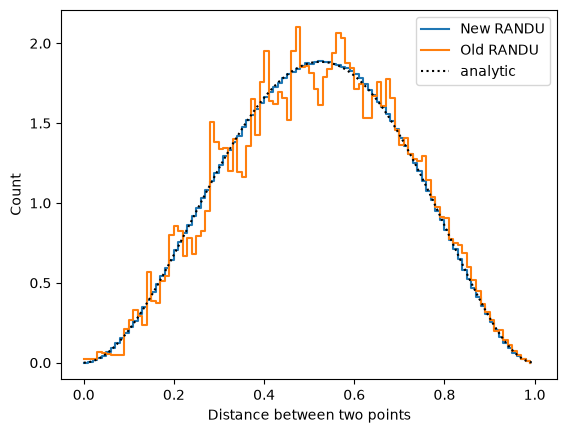

In [4]:
from scipy.spatial.distance import pdist
from scipy.integrate import quad

old, new = randu(9000)

x,y,z = old[:-2], old[1:-1], old[2:]
ind = np.where((x-0.5)**2+(y-0.5)**2+(z-0.5)**2<0.25)
x = x[ind]
y = y[ind]
z=z[ind]
points = np.column_stack((x, y, z))
distances = pdist(points)
hist1, edges1 = np.histogram(distances, bins=100, range=(0, 1), density=True)

x,y,z = new[:-2], new[1:-1], new[2:]
ind = np.where((x-0.5)**2+(y-0.5)**2+(z-0.5)**2<0.25)
x = x[ind]
y = y[ind]
z=z[ind]
points = np.column_stack((x, y, z))
distances = pdist(points)
hist2, edges2 = np.histogram(distances, bins=100, range=(0, 1), density=True)

plt.figure()
plt.step(edges2[:-1], hist2, where='post', label=r'New RANDU')
plt.step(edges1[:-1], hist1, where='post', label=r'Old RANDU')
# analytic (the formula is for R=1 but we have R=0.5 so rescale when plotting)
x = np.linspace(0,2,100)
f = lambda x: (3/16)*x*x*(4+x)*(2-x)**2
plt.plot(x/2,2*f(x),'k:', label='analytic')
plt.xlabel('Distance between two points')
plt.ylabel('Count')
plt.legend()
plt.show()

The old RANDU does not have good coverage in 3D, as we saw in class. In 3D the samples falls onto 15 discrete planes. We can see in the histogram there is a series of peaks that correspond to these planes. The new RANDU on the other hand agrees well with the analytic formula. 

## 2. Ising model

In [13]:
def run_ising(beta):

    N = 32
    Nspins = N*N
    ntrials = 10**5

    # Populate the array with random spins (+1 or -1)
    #spins = -1 + rng.integers(2, size = Nspins) * 2
    # or start with all spins aligned: gives faster convergence at low T
    spins = np.ones(Nspins)

    M = np.zeros(ntrials)
    M[0] = np.sum(spins)/Nspins  # starting point

    # Compute the random numbers to use for accepting the jump in advance
    u = rng.uniform(size=ntrials)
    
    for i in range(ntrials-1):
        
        # Choose spin at random
        j = rng.integers(Nspins)
    
        # Compute energy change if this spin were to flip
        delta_E = 2*spins[j] * (spins[j-1] + spins[(j+1) % Nspins] + spins[j-N] + spins[(j+N) % Nspins])
    
        # Attempt flip
        if u[i] <= np.exp(-beta*delta_E):
            spins[j] = -spins[j]

        # Store magnetization
        M[i+1] = np.sum(spins)/Nspins
        
    # remove the first 20% (burn in)
    return M[int(ntrials/5):]

T =  1.0
T =  1.5000000000000004
T =  2.000000000000001
T =  2.5000000000000013
T =  3.0000000000000018
T =  3.500000000000002
T =  4.000000000000003
time =  16.188779830932617


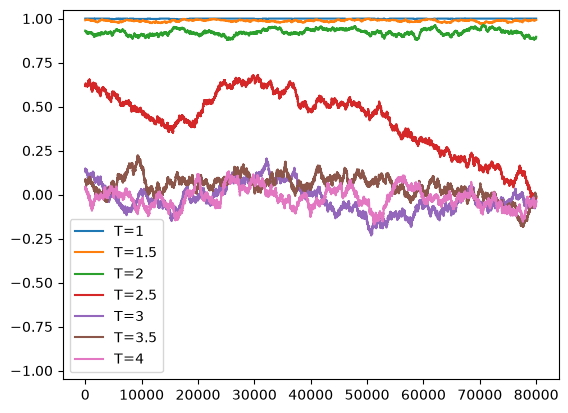

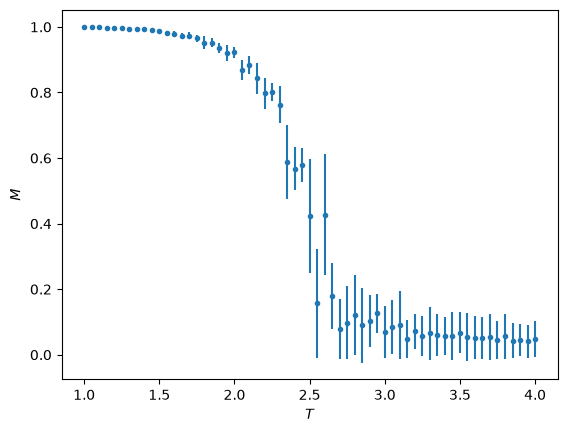

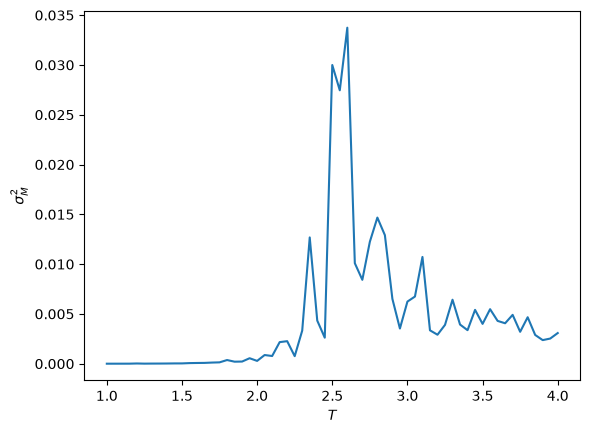

In [14]:
import time
t0 = time.time()

T_vals = np.arange(1.0,4.05,0.05)

M_vals = np.zeros_like(T_vals)
chi_vals = np.zeros_like(T_vals)

for i, T in enumerate(T_vals):
    M = run_ising(1/T)
    M_vals[i] = np.mean(np.abs(M))
    chi_vals[i] = np.var(M)

    if (abs(np.floor(T*2)-(T*2))<1e-5):
        print("T = ", T)
        t = np.arange(len(M))
        plt.plot(t, M, label = "T=%g" % (T,))

print('time = ', time.time()-t0)
        
plt.ylim((-1.05,1.05))
plt.legend()
plt.show()
        
plt.clf()
plt.errorbar(T_vals, M_vals, np.sqrt(chi_vals), fmt='.')
plt.ylabel(r'$M$')
plt.xlabel(r'$T$')
plt.show()

plt.clf()
plt.plot(T_vals, chi_vals)
plt.ylabel(r'$\sigma_M^2$')
plt.xlabel(r'$T$')
plt.show()